In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
img = cv2.imread("wallimage.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)
img = cv2.resize(img, (224, 224))
# output_img = np.zeros_like(img, dtype=np.float32)
output_img = img.copy()

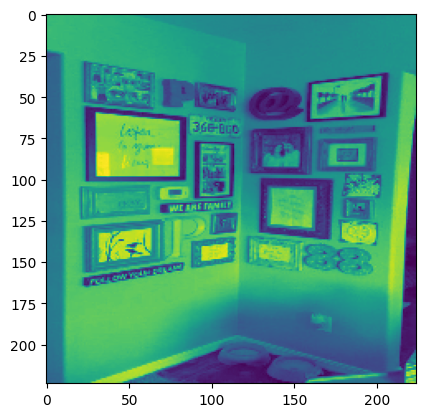

In [4]:
plt.imshow(img)

In [5]:
kernel_dim = 3
l = []
for i in range(kernel_dim//2, img.shape[0]-kernel_dim//2):
    for j in range(kernel_dim//2, img.shape[1]-kernel_dim//2):
        operand_img = img[i-kernel_dim//2:i+kernel_dim//2+1, j-kernel_dim//2: j+kernel_dim//2+1]
        Ix = (operand_img[0, 1] - operand_img[0, 0]) + (operand_img[1, 1] - operand_img[1, 0]) + (operand_img[2, 1] - operand_img[2, 0])
        Iy = (operand_img[1, 0] - operand_img[0, 0]) + (operand_img[1, 1] - operand_img[0, 1]) + (operand_img[1, 2] - operand_img[0, 2])
        
        M = np.array([[Ix**2, Ix*Iy], [Ix*Iy, Iy**2]])
        eigenvalues = np.linalg.eigvals(M)
        eigenvalues_sum = np.sum(eigenvalues)
        if eigenvalues_sum > 10**3:
            output_img = cv2.circle(output_img, (j, i), 1, (0, 0, 0), -1)


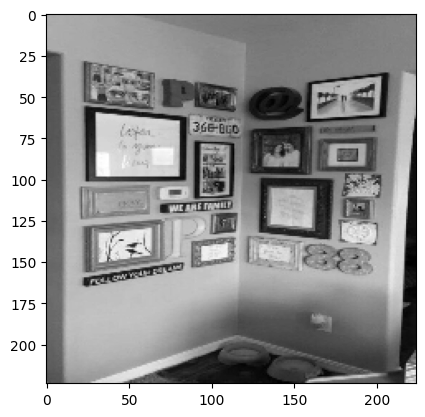

In [6]:
plt.imshow(img, cmap="gray")

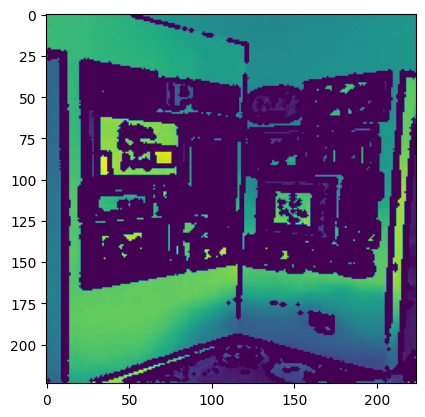

In [7]:
plt.imshow(output_img)

In [ ]:
q